<h1> Concentration dependence of bimolecular reactions</h1>

<h2> Python code 2-06 accompanying <i>Molecular Machines</i></h2>

<p>G. Woehlke 2025 ff (converted from Wolfram Mathematica, aided by A.I.)</p>

Given is the following system, in which one molecule encounters another one and can bind reversibly:

   A + B &harr; C 
   
This might describe a protein that binds a ligand, e.g. myoglobin and $O_2$ or similar (important: only one ligand binding site, no cooperative effects as in hemoglobin). Concentrations A, B and C will change with velocities $x'(t)$, $y'(t)$, and $z't)$:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import ipywidgets as widgets

def bimolecular_sim(isize=720, grid=None, thn=0.005, fs=14, k12=10.0, k21=1.0, cy=1.0, zeitachse=0.8):
    """
    Simulate A + B <-> C with initial B concentration cy
    and rate constants k12, k21. 
    """
    # ODE for z(t)
    def dz_dt(t, z):
        x = x0 - z
        y = cy - z
        return k12 * x * y - k21 * z
    
    # Initial conditions
    x0 = 1.0
    z0 = 0.0
    y0 = [x0, z0]

    t_span = (0, 10)
    t_eval = np.linspace(0, zeitachse, 400)

#    sol = solve_ivp(odes, t_span, y0, t_eval=t_eval, method='RK45')
    sol = solve_ivp(dz_dt, t_span, [z0], t_eval=t_eval)

#    x_t = sol.y[0]
#    z_t = sol.y[1]
    z_t = sol.y[0]
    x_t = x0 - z_t
    y_t = cy - z_t

    # Equilibrium approximations (from Mathematica)
    eq1 = ((-1 + k12/k21 - cy*k12/k21)+(np.sqrt(4*k12/k21 + (-1 + k12/k21 - cy*k12/k21)**2))) / (2*k12/k21)
    eq2 = (-1 + (2+1-cy)*k12/k21 + np.sqrt(4*k12/k21 + (1 - 1 + cy*k12/k21)**2)) / (4*k12/k21)

    # Plotting
    plt.figure(figsize=(isize/100, isize/140))
    plt.plot(t_eval, x_t, color='blue', linewidth=thn*100)
    plt.plot(t_eval, z_t, color=(0.65,0.65,1), linewidth=thn*100)
    plt.axhline(eq1, color='gray', linestyle=':')
    plt.axhline(eq2, color='gray', linestyle='--')

    if grid:
        plt.grid(True)

    plt.xlabel("time / s", fontsize=fs)
    plt.ylabel("concentration (over time)", fontsize=fs)
    plt.title("Bimolecular reaction A + B ⇌ C", fontsize=fs)

    # Info panel
    info_text = (
        f"$c_B$  = {cy} M\n"
        f"$k12$ = {k12:.2f} $M^{-1} \cdot s^{-1}$\n"
        f"k21 = {k21:.2f} $s^{-1}$\n"
        f"$K_D$ = {k21/k12:.2f} M"
    )
    plt.text(0.5*zeitachse, 0.8, info_text, fontsize=9, bbox=dict(facecolor='white'))

    plt.ylim(0, 1.04)
    plt.show()


# Interactive sliders
widgets.interact(
    bimolecular_sim,
    isize=widgets.Dropdown(options=[450,650,720,950,1080,1450], value=950, description='Image Size'),
    grid=widgets.Dropdown(options=[("None",False),("Automatic",True)], value=False),
    thn=widgets.Dropdown(options=[0.01,0.025,0.035,0.05,0.067,0.08], value=0.025, description='Line Thickness'),
    fs=widgets.Dropdown(options=[9,12,14,18,24], value=14, description='Font Size'),
    k12=widgets.FloatSlider(value=10.0, min=0.01, max=25, step=0.5, description='k12'),
    k21=widgets.FloatSlider(value=1.0, min=0.01, max=25, step=0.5, description='k21'),
    cy=widgets.FloatSlider(value=1.0, min=0.01, max=10.0, step=0.1, description='init conc. B'),
    zeitachse=widgets.FloatSlider(value=0.8, min=0.2, max=1.0, step=0.1, description='time axis')
)

interactive(children=(Dropdown(description='Image Size', index=3, options=(450, 650, 720, 950, 1080, 1450), va…

<function __main__.bimolecular_sim(isize=720, grid=None, thn=0.005, fs=14, k12=10.0, k21=1.0, cy=1.0, zeitachse=0.8)>

<h3>Figure legend</h3>
<p><span style="color:darkblue">Figure 1</span>: Numerical simulation of the bimolecular association of A and B using <i>SciPy</i>'s <i>solve_ivp</i> initial value problem solver. Initial values are $c_A(0) = 1.$, $c_C(0)$, both rates $k_{12}$ and $k_{21}$, as well as the initial concentration of the product, $c_{B}(0)$ may be varied. </p>
<p>The <i>lower</i>, dotted horizontal line indicates the equilibrium concentration of A, the <i>top</i>, dashed line shows the level when half of substrate A has reacted. Remember that "half of the substrate concentration" does <b>not</b> mean $c_A = \frac{1}{2} c_{A,0}$ but that the equilibrium concentration has been reached half way. From this, the half-life time can be read out. </p>

## Concentration dependence of the reaction

A table of half-life times in dependence of the initial concentration of B may be read from the graph above. The _**rates**_ are $log{(2.)} \times t_{1/2} ^{-1}$, the inverse of these half-life times, and follow the concentration dependence below. Reading out a number of rates at increasing concentrations of B, we get:

In [2]:
import numpy as np

x_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 7.5, 10.0]
y_values = [np.log(2)/0.065, np.log(2)/0.065, np.log(2)/0.066, np.log(2)/0.066,
            np.log(2)/0.067, np.log(2)/0.064, np.log(2)/0.0605, np.log(2)/0.047,
            np.log(2)/0.036, np.log(2)/0.029, np.log(2)/0.024, np.log(2)/0.018,
            np.log(2)/0.014, np.log(2)/0.00952, np.log(2)/0.00717]

data = list(zip(x_values, y_values))

In [3]:
print(data[:5])
# Output:
# [(0.1, 10.666666666666666), (0.2, 10.666666666666666), ...]

[(0.1, 10.663802777845312), (0.2, 10.663802777845312), (0.3, 10.50223000848402), (0.4, 10.50223000848402), (0.5, 10.345480306864854)]


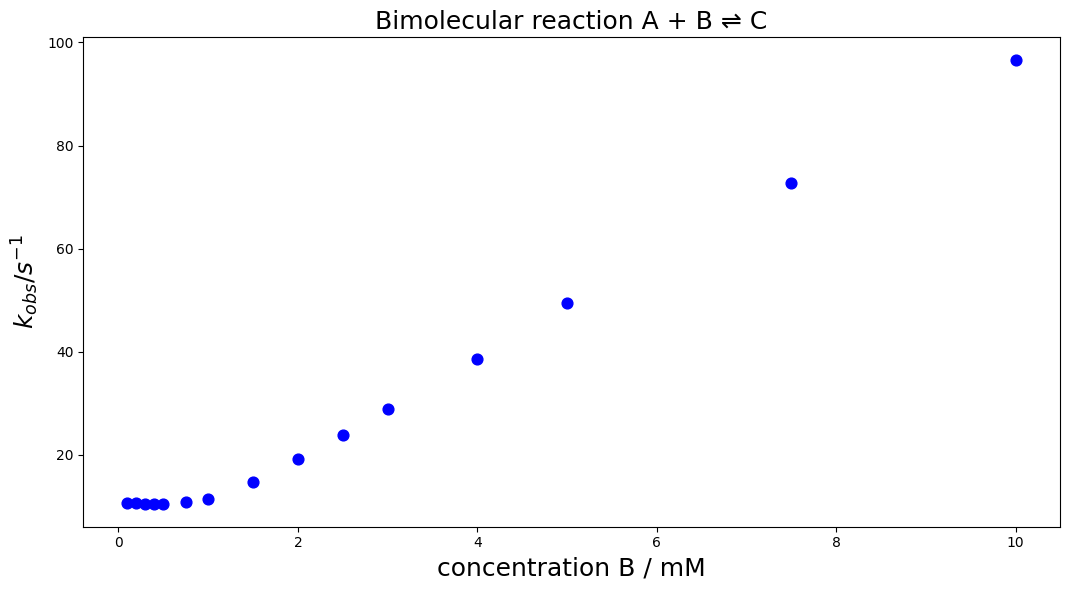

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Data (from previous step)
x_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 7.5, 10.0]
y_values = [np.log(2)/0.065, np.log(2)/0.065, np.log(2)/0.066, np.log(2)/0.066,
            np.log(2)/0.067, np.log(2)/0.064, np.log(2)/0.0605, np.log(2)/0.047,
            np.log(2)/0.036, np.log(2)/0.029, np.log(2)/0.024, np.log(2)/0.018,
            np.log(2)/0.014, np.log(2)/0.00952, np.log(2)/0.00717]

plt.figure(figsize=(1080/100, 6))  # ImageSize -> 1080 in Mathematica

# Plot points with blue circles
plt.scatter(x_values, y_values, color='blue', s=60, label='Data')

plt.xlabel("concentration B / mM", fontsize=18)
plt.ylabel("$k_{obs} / s^{-1}$", fontsize=18)
plt.title("Bimolecular reaction A + B ⇌ C", fontsize=18)

plt.grid(False)
plt.tight_layout()
plt.show()

<h3>Figure legend</h3>
<p><span style="color:darkblue">Figure 2</span>: Concentration dependence of the bimolecular association reaction A + B ⇌ C </p>
<p> The initial concentration of A is fixed at $c_{A,0}=1 M$, the forward rate is $k_{12}=10. M^{-1} \cdot s^{-1}$, the backward rate $k_{21}=0.1 s^{-1}$. The rates are read out from figure 1 above, and show a linear dependence as soon as the (substrate) concentration of B exceeds the (enzyme) concentration of A. The slope from 2 mM to 10 mm corresponds to $k_{\text{apparent}} =(139.5 - 27.8)/8 = 13.96 M^{-1} s^{-1}$.</p>